# Project Title:
Labour Market Analytics: Analyzing Employment Resilience Across Indian States


## Objective

*  Merge Periodic Labour Force Survey (PLFS)datasets (LFPR, UR, WPR, sector-wise employment) for 22 Indian states, 2018–2024, into one clean dataset using Python.

* Analyze trends and disparities across states, gender, and time, with focus on the COVID-19 period (2019–2022).

* Compute descriptive statistics (mean, % change, YoY growth) to measure shifts in each indicator.

* Rank states by employment shock and recovery using rule-based thresholds.

* Study sector-wise shifts (agriculture vs non-agriculture) to understand structural employment changes.

* Visualize findings through an interactive Power BI dashboard.

Outcome

* A clean, merged, analysis-ready dataset combining LFPR, Unemployment Rate, WPR, and sector-wise employment data across all Indian states (2018–2024).

* A clear understanding of how each state's labour market indicators moved across the three phases — pre-COVID (2019), shock (2020), and recovery (2022).

* Identification of states that were hit hardest by the pandemic (sharpest UR spike, biggest LFPR/WPR drop) versus those that stayed relatively stable.

* Identification of states that recovered fastest by 2022 versus those still lagging behind pre-COVID employment levels.

* Insights into sector-wise shifts in employment (e.g., movement between agriculture and non-agriculture, or formal/informal patterns) during and after the pandemic.

* A simple, transparent ranking or categorization of states (e.g., "high resilience," "moderate resilience," "low resilience") based on rule-based comparisons of their indicator changes

* An interactive Power BI dashboard that lets users filter/explore trends by state, year, quarter, gender, and age group.

* A reusable Python-based data pipeline (merge → clean → analyze) that could be extended to future PLFS data releases with minimal changes.

* A practical demonstration of how data analytics can surface actionable, real-world insights into labour market resilience — useful for policy discussions, academic reporting, or further research.

## Domain
Employment

# Dataset Information

Source: https://indiadataportal.com/p/employment

Year / Timeline: 2018-2024

Rows x Columns: 4347*12

Dataset Column/features Description:

* State_code-	Unique code identifying each Indian state
* State_name-	Name of the state
* Year-	Survey year (2018, 2019, 2020, 2021, 2022, 2023, 2024)
* Quarter	Survey quarter (Q1–Q4)
* Age_group-	Age group of the surveyed population
* Gender-	Gender category
* LFPR-	Labour Force Participation Rate (%)
* UR-	Unemployment Rate (%)
* WPR-	Worker Population Ratio (%)
* Agriculture_sector-	Share of employment in the agriculture sector (%)
* Secondary_sector-	Share of employment in the secondary/industrial sector (%)
* Tertiary_sector-	Share of employment in the tertiary/services sector (%)



# **Stage 1 – Problem Definition and Dataset Selection**

In [ ]:
import pandas as pd
import numpy as np

lfpr = pd.read_csv("/content/lfpr.csv")
lfpr

,id,year,quarter,state_name,age_group,gender,lfpr,state_code
0,0,2019,April-June,Andhra Pradesh,15-29 Years,Male,54.0,28
1,1,2019,April-June,Assam,15-29 Years,Male,52.3,18
2,2,2019,April-June,Bihar,15-29 Years,Male,45.2,10
3,3,2019,April-June,Chhattisgarh,15-29 Years,Male,59.1,22
4,4,2019,April-June,Delhi,15-29 Years,Male,55.0,7
...,...,...,...,...,...,...,...,...
5170,5170,2024,January-March,Uttarakhand,All,Person,36.6,5
5171,5171,2024,January-March,Uttar Pradesh,All,Person,34.9,9
5172,5172,2024,January-March,West Bengal,All,Person,43.9,19
5173,5173,2024,January-March,Jammu And Kashmir,All,Person,39.9,1


In [ ]:
UR= pd.read_csv("/content/UR.csv")
UR

,id,year,quarter,state_name,age_group,gender,UR,state_code
0,0,2019,April-June,Andhra Pradesh,15-29 Years,Male,25.9,28
1,1,2019,April-June,Assam,15-29 Years,Male,25.3,18
2,2,2019,April-June,Bihar,15-29 Years,Male,29.8,10
3,3,2019,April-June,Chhattisgarh,15-29 Years,Male,22.9,22
4,4,2019,April-June,Delhi,15-29 Years,Male,23.0,7
...,...,...,...,...,...,...,...,...
4756,4756,2024,January-March,Uttarakhand,All,Person,8.0,5
4757,4757,2024,January-March,Uttar Pradesh,All,Person,8.3,9
4758,4758,2024,January-March,West Bengal,All,Person,5.2,19
4759,4759,2024,January-March,Jammu And Kashmir,All,Person,11.0,1


In [ ]:
Wpr= pd.read_csv("/content/Wpr.csv")
Wpr

,id,year,quarter,state_name,age_group,gender,Wpr,state_code
0,0,2019,April-June,Andhra Pradesh,15-29 Years,Male,40.0,28
1,1,2019,April-June,Assam,15-29 Years,Male,39.0,18
2,2,2019,April-June,Bihar,15-29 Years,Male,31.8,10
3,3,2019,April-June,Chhattisgarh,15-29 Years,Male,45.5,22
4,4,2019,April-June,Delhi,15-29 Years,Male,42.4,7
...,...,...,...,...,...,...,...,...
5170,5170,2024,January-March,Uttarakhand,All,Person,33.7,5
5171,5171,2024,January-March,Uttar Pradesh,All,Person,32.0,9
5172,5172,2024,January-March,West Bengal,All,Person,41.6,19
5173,5173,2024,January-March,Jammu And Kashmir,All,Person,35.5,1


In [ ]:
sectors= pd.read_csv("/content/sectors.csv")
sectors

,id,year,quarter,state_name,gender,agriculture_sector,secondary_sector,tertiary_sector,state_code
0,0,2019,April-June,Andhra Pradesh,Male,4.57,32.98,62.45,28
1,1,2019,April-June,Assam,Male,5.91,24.70,69.38,18
2,2,2019,April-June,Bihar,Male,7.24,25.24,67.53,10
3,3,2019,April-June,Chhattisgarh,Male,7.59,34.28,58.14,22
4,4,2019,April-June,Delhi,Male,0.32,30.21,69.46,7
...,...,...,...,...,...,...,...,...,...
1586,1586,2024,January-March,Uttarakhand,Person,4.66,28.59,66.78,5
1587,1587,2024,January-March,Uttar Pradesh,Person,7.58,32.17,60.27,9
1588,1588,2024,January-March,West Bengal,Person,3.37,32.30,64.31,19
1589,1589,2024,January-March,Jammu And Kashmir,Person,7.63,29.18,63.19,1


**Checking null**

In [ ]:
lfpr.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5175 entries, 0 to 5174
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   id          5175 non-null   int64  
 1   year        5175 non-null   int64  
 2   quarter     5175 non-null   object 
 3   state_name  5175 non-null   object 
 4   age_group   5175 non-null   object 
 5   gender      5175 non-null   object 
 6   lfpr        5175 non-null   float64
 7   state_code  5175 non-null   int64  
dtypes: float64(1), int64(3), object(4)
memory usage: 323.6+ KB


In [ ]:
UR.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4761 entries, 0 to 4760
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   id          4761 non-null   int64  
 1   year        4761 non-null   int64  
 2   quarter     4761 non-null   object 
 3   state_name  4761 non-null   object 
 4   age_group   4761 non-null   object 
 5   gender      4761 non-null   object 
 6   UR          4761 non-null   float64
 7   state_code  4761 non-null   int64  
dtypes: float64(1), int64(3), object(4)
memory usage: 297.7+ KB


In [ ]:
Wpr.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5175 entries, 0 to 5174
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   id          5175 non-null   int64  
 1   year        5175 non-null   int64  
 2   quarter     5175 non-null   object 
 3   state_name  5175 non-null   object 
 4   age_group   5175 non-null   object 
 5   gender      5175 non-null   object 
 6   Wpr         5175 non-null   float64
 7   state_code  5175 non-null   int64  
dtypes: float64(1), int64(3), object(4)
memory usage: 323.6+ KB


In [ ]:
sectors.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1591 entries, 0 to 1590
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   id                  1591 non-null   int64  
 1   year                1591 non-null   int64  
 2   quarter             1591 non-null   object 
 3   state_name          1591 non-null   object 
 4   gender              1591 non-null   object 
 5   agriculture_sector  1562 non-null   float64
 6   secondary_sector    1591 non-null   float64
 7   tertiary_sector     1591 non-null   float64
 8   state_code          1591 non-null   int64  
dtypes: float64(3), int64(3), object(3)
memory usage: 112.0+ KB


**Checking duplicates**-
Full rows

In [ ]:
lfpr.duplicated().sum()

np.int64(0)

In [ ]:
UR.duplicated().sum()

np.int64(0)

In [ ]:
Wpr.duplicated().sum()

np.int64(0)

In [ ]:
sectors.duplicated().sum()

np.int64(0)

**Checking duplicates**-
Specific columns

In [ ]:
key_cols_full = ['state_code', 'state_name', 'year', 'quarter', 'age_group', 'gender']
lfpr.duplicated(key_cols_full).sum()
print("lfpr duplicate value:", lfpr.duplicated(key_cols_full).sum())

lfpr duplicate value: 276


In [ ]:
UR.duplicated(key_cols_full).sum()
print("UR duplicate value:", UR.duplicated(key_cols_full).sum())

UR duplicate value: 0


In [ ]:
Wpr.duplicated(key_cols_full).sum()
print("Wpr duplicate value:", Wpr.duplicated(key_cols_full).sum())

Wpr duplicate value: 276


In [ ]:
key_cols_sector = ['state_code', 'state_name', 'year', 'quarter', 'gender']
sectors.duplicated(key_cols_sector).sum()
print("sectors duplicate value:",sectors.duplicated(key_cols_sector).sum())

sectors duplicate value: 4


## Duplicate rows (both the original and the repeat): LFPR

In [ ]:
key_cols_full = ['state_code', 'state_name', 'year', 'quarter', 'age_group', 'gender']
dup_lfpr = lfpr[lfpr.duplicated(key_cols_full, keep=False)]
print(dup_lfpr.sort_values(key_cols_full).head(20))

        id  year           quarter         state_name           age_group  \
3117  3113  2018        April-June  Jammu And Kashmir  15 Years And Above   
3188  3182  2018        April-June  Jammu And Kashmir  15 Years And Above   
2907  2906  2018        April-June  Jammu And Kashmir         15-29 Years   
2977  2975  2018        April-June  Jammu And Kashmir         15-29 Years   
3321  3320  2018        April-June  Jammu And Kashmir                 All   
3389  3389  2018        April-June  Jammu And Kashmir                 All   
3281  3274  2018    July-September  Jammu And Kashmir  15 Years And Above   
4633  4631  2018    July-September  Jammu And Kashmir  15 Years And Above   
3141  3136  2018    July-September  Jammu And Kashmir  15 Years And Above   
3211  3205  2018    July-September  Jammu And Kashmir  15 Years And Above   
3070  3067  2018    July-September  Jammu And Kashmir         15-29 Years   
4563  4562  2018    July-September  Jammu And Kashmir         15-29 Years   

In [ ]:
lfpr.shape

(4347, 7)

In [ ]:
print(dup_lfpr['year'].value_counts())
print(dup_lfpr['quarter'].value_counts())

year
2018    552
Name: count, dtype: int64
quarter
July-September      276
April-June          138
October-December    138
Name: count, dtype: int64


In [ ]:
print(dup_lfpr['state_name'].value_counts())

state_name
Bihar                24
Andhra Pradesh       24
Assam                24
Chhattisgarh         24
Delhi                24
Gujarat              24
Haryana              24
Himachal Pradesh     24
Jammu And Kashmir    24
Jharkhand            24
Karnataka            24
Kerala               24
Madhya Pradesh       24
Maharashtra          24
Odisha               24
Punjab               24
Rajasthan            24
Tamil Nadu           24
Telangana            24
Uttarakhand          24
Uttar Pradesh        24
West Bengal          24
All-India            24
Name: count, dtype: int64


## Duplicate rows: WPR

In [ ]:
key_cols_full = ['state_code', 'state_name', 'year', 'quarter', 'age_group', 'gender']
dup_Wpr = Wpr[Wpr.duplicated(key_cols_full, keep=False)]
print(dup_Wpr.sort_values(key_cols_full).head(20))

        id  year           quarter         state_name           age_group  \
3114  3113  2018        April-June  Jammu And Kashmir  15 Years And Above   
3183  3182  2018        April-June  Jammu And Kashmir  15 Years And Above   
2906  2906  2018        April-June  Jammu And Kashmir         15-29 Years   
2975  2975  2018        April-June  Jammu And Kashmir         15-29 Years   
3321  3320  2018        April-June  Jammu And Kashmir                 All   
3389  3389  2018        April-June  Jammu And Kashmir                 All   
3275  3274  2018    July-September  Jammu And Kashmir  15 Years And Above   
4631  4631  2018    July-September  Jammu And Kashmir  15 Years And Above   
3137  3136  2018    July-September  Jammu And Kashmir  15 Years And Above   
3206  3205  2018    July-September  Jammu And Kashmir  15 Years And Above   
3067  3067  2018    July-September  Jammu And Kashmir         15-29 Years   
4562  4562  2018    July-September  Jammu And Kashmir         15-29 Years   

Dropping 2018 datas:

2018 was excluded because LFPR and WPR contained conflicting values for the same state, period, age group and gender, and the source had no field to tell them apart.

In [ ]:
lfpr = lfpr[lfpr['year'] != 2018].reset_index(drop=True)
UR = UR[UR['year'] != 2018].reset_index(drop=True)
Wpr = Wpr[Wpr['year'] != 2018].reset_index(drop=True)
sectors = sectors[sectors['year'] != 2018].reset_index(drop=True)

checking for duplicates after dropping 2018

In [ ]:
key_cols_full = ['state_code', 'state_name', 'year', 'quarter', 'age_group', 'gender']
lfpr.duplicated(key_cols_full).sum()

np.int64(0)

In [ ]:
lfpr.shape

(4347, 7)

In [ ]:
UR.duplicated(key_cols_full).sum()

np.int64(0)

In [ ]:
UR.shape

(4347, 7)

In [ ]:
Wpr.duplicated(key_cols_full).sum()

np.int64(0)

In [ ]:
Wpr.shape

(4347, 7)

In [ ]:
key_cols_sector = ['state_code', 'state_name', 'year', 'quarter', 'gender']
sectors.duplicated(key_cols_sector).sum()

np.int64(4)

## Removing duplicates from sector table

In [ ]:
key_cols_sector = ['state_code', 'state_name', 'year', 'quarter', 'gender']

dup_sectors = sectors[sectors.duplicated(key_cols_sector, keep=False)]
print(dup_sectors.sort_values(key_cols_sector))

        id  year           quarter state_name  gender  agriculture_sector  \
924    924  2022        April-June      Delhi  Female                 0.0   
1314  1452  2022        April-June      Delhi  Female                 NaN   
855    855  2022     January-March      Delhi  Female                 NaN   
1244  1244  2022     January-March      Delhi  Female                 0.0   
441    441  2022    July-September      Delhi  Female                 NaN   
966    966  2022    July-September      Delhi  Female                 0.0   
481    510  2022  October-December      Delhi  Female                 NaN   
967    967  2022  October-December      Delhi  Female                 0.0   

      secondary_sector  tertiary_sector  state_code  
924              18.66            81.34           7  
1314             18.66            81.34           7  
855              16.45            83.57           7  
1244             16.45            83.57           7  
441              24.38            75

In every pair, secondary and tertiary are identical, and the only difference is agriculture, one row says 0.0 and the other says NaN. So iam keeping the 0.0 row and discarding the NaN

In [ ]:
key_cols_sector = ['state_code', 'state_name', 'year', 'quarter', 'gender']

sectors = (
    sectors.sort_values('agriculture_sector')       # NaN goes last
           .drop_duplicates(subset=key_cols_sector, keep='first')
           .sort_index()
           .reset_index(drop=True)
)

print("Sectors duplicate keys:", sectors.duplicated(key_cols_sector).sum())  # Re-check
print("Remaining shape:", sectors.shape)

Sectors duplicate keys: 0
Remaining shape: (1449, 8)


In [ ]:
print(sectors.isnull().sum())

year                   0
quarter                0
state_name             0
gender                 0
agriculture_sector    23
secondary_sector       0
tertiary_sector        0
state_code             0
dtype: int64


This table displays NaN in Agriculture column

In [ ]:
sectors[sectors['agriculture_sector'].isnull()]

,year,quarter,state_name,gender,agriculture_sector,secondary_sector,tertiary_sector,state_code
1426,2019,April-June,Delhi,Female,NaN,21.37,78.63,7
1427,2019,July-September,Delhi,Male,NaN,31.86,68.13,7
1428,2019,July-September,Delhi,Female,NaN,22.33,77.68,7
1429,2019,July-September,Delhi,Person,NaN,30.19,69.79,7
1430,2019,October-December,Delhi,Female,NaN,17.46,82.54,7
1431,2020,January-March,Delhi,Female,NaN,15.25,84.75,7
1432,2020,April-June,Delhi,Female,NaN,10.73,89.27,7
1433,2020,July-September,Delhi,Female,NaN,7.58,92.43,7
1434,2023,January-March,Delhi,Female,NaN,20.71,79.30,7
1435,2023,April-June,Delhi,Female,NaN,27.40,72.57,7


Duplicate copy of sector df is created to check sum of secondary and tertiary sector gives 100%

In [ ]:
na_rows = sectors[sectors['agriculture_sector'].isnull()].copy()
na_rows['sum_sec_ter'] = na_rows['secondary_sector'] + na_rows['tertiary_sector']
print(na_rows[['state_name', 'year', 'quarter', 'gender',
               'secondary_sector', 'tertiary_sector', 'sum_sec_ter']])
print(na_rows['state_name'].value_counts())

     state_name  year           quarter  gender  secondary_sector  \
1426      Delhi  2019        April-June  Female             21.37   
1427      Delhi  2019    July-September    Male             31.86   
1428      Delhi  2019    July-September  Female             22.33   
1429      Delhi  2019    July-September  Person             30.19   
1430      Delhi  2019  October-December  Female             17.46   
1431      Delhi  2020     January-March  Female             15.25   
1432      Delhi  2020        April-June  Female             10.73   
1433      Delhi  2020    July-September  Female              7.58   
1434      Delhi  2023     January-March  Female             20.71   
1435      Delhi  2023        April-June  Female             27.40   
1436      Delhi  2023    July-September  Female             11.97   
1437      Delhi  2021  October-December  Female              8.74   
1438      Delhi  2021        April-June    Male             27.65   
1439      Delhi  2021        April

Since all the values are nearby 100 we are going to fill NaN with zero

In [ ]:
sectors['agriculture_sector'] = sectors['agriculture_sector'].fillna(0)

In [ ]:
sectors['agriculture_sector'].isnull().sum()  #checking does null exist

np.int64(0)

In [ ]:
sectors.shape

(1449, 8)

# Merging 4 tables

In [ ]:
lfpr = lfpr.drop(columns=['id'], errors='ignore')
UR = UR.drop(columns=['id'], errors='ignore')
Wpr = Wpr.drop(columns=['id'], errors='ignore')
sectors = sectors.drop(columns=['id'], errors='ignore')

In [ ]:
key_cols_full = ['state_code', 'state_name', 'year', 'quarter', 'age_group', 'gender']
key_cols_sector = ['state_code', 'state_name', 'year', 'quarter', 'gender']


# Merging LFPR + UR + WPR

df = lfpr.merge(UR, on=key_cols_full, how='outer')
df = df.merge(Wpr, on=key_cols_full, how='outer')

print("After merging LFPR + UR + WPR:", df.shape)
print(df.isna().sum())



After merging LFPR + UR + WPR: (4347, 9)
year          0
quarter       0
state_name    0
age_group     0
gender        0
lfpr          0
state_code    0
UR            0
Wpr           0
dtype: int64


In [ ]:
# Merging sector data (reduced key, no age_group)
df = df.merge(sectors, on=key_cols_sector, how='outer')

print("\nAfter merging sector data:", df.shape)
print(df.isna().sum())


After merging sector data: (4347, 12)
year                  0
quarter               0
state_name            0
age_group             0
gender                0
lfpr                  0
state_code            0
UR                    0
Wpr                   0
agriculture_sector    0
secondary_sector      0
tertiary_sector       0
dtype: int64


In [ ]:
# Final check
print("\n Final columns:", df.columns.tolist())


 Final columns: ['year', 'quarter', 'state_name', 'age_group', 'gender', 'lfpr', 'state_code', 'UR', 'Wpr', 'agriculture_sector', 'secondary_sector', 'tertiary_sector']


In [ ]:
print(df.head())

   year     quarter         state_name           age_group  gender  lfpr  \
0  2019  April-June  Jammu And Kashmir  15 Years And Above  Female  18.2   
1  2019  April-June  Jammu And Kashmir         15-29 Years  Female  22.9   
2  2019  April-June  Jammu And Kashmir                 All  Female  14.6   
3  2019  April-June  Jammu And Kashmir  15 Years And Above    Male  72.1   
4  2019  April-June  Jammu And Kashmir         15-29 Years    Male  54.7   

   state_code    UR   Wpr  agriculture_sector  secondary_sector  \
0           1  30.1  12.8               14.80             22.50   
1           1  53.8  10.6               14.80             22.50   
2           1  29.7  10.2               14.80             22.50   
3           1   6.4  67.5                3.28             27.99   
4           1  20.6  43.4                3.28             27.99   

   tertiary_sector  
0            62.68  
1            62.68  
2            62.68  
3            68.72  
4            68.72  


Saving merged table as csv file

In [ ]:
# Save
df.to_csv('Merged_labour_market_data.csv', index=False)
print("\n Saved as Merged_labour_market_data.csv")


 Saved as Merged_labour_market_data.csv


In [ ]:
from google.colab import files
files.download('Merged_labour_market_data.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Initial EDA : After merging the tables

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4347 entries, 0 to 4346
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   year                4347 non-null   int64  
 1   quarter             4347 non-null   object 
 2   state_name          4347 non-null   object 
 3   age_group           4347 non-null   object 
 4   gender              4347 non-null   object 
 5   lfpr                4347 non-null   float64
 6   state_code          4347 non-null   int64  
 7   UR                  4347 non-null   float64
 8   Wpr                 4347 non-null   float64
 9   agriculture_sector  4347 non-null   float64
 10  secondary_sector    4347 non-null   float64
 11  tertiary_sector     4347 non-null   float64
dtypes: float64(6), int64(2), object(4)
memory usage: 407.7+ KB


In [ ]:
df.head(20)


,year,quarter,state_name,age_group,gender,lfpr,state_code,UR,Wpr,agriculture_sector,secondary_sector,tertiary_sector
0,2019,April-June,Jammu And Kashmir,15 Years And Above,Female,18.2,1,30.1,12.8,14.80,22.50,62.68
1,2019,April-June,Jammu And Kashmir,15-29 Years,Female,22.9,1,53.8,10.6,14.80,22.50,62.68
2,2019,April-June,Jammu And Kashmir,All,Female,14.6,1,29.7,10.2,14.80,22.50,62.68
3,2019,April-June,Jammu And Kashmir,15 Years And Above,Male,72.1,1,6.4,67.5,3.28,27.99,68.72
4,2019,April-June,Jammu And Kashmir,15-29 Years,Male,54.7,1,20.6,43.4,3.28,27.99,68.72
5,2019,April-June,Jammu And Kashmir,All,Male,56.4,1,6.4,52.8,3.28,27.99,68.72
6,2019,April-June,Jammu And Kashmir,15 Years And Above,Person,46.1,1,10.9,41.1,5.04,27.16,67.81
7,2019,April-June,Jammu And Kashmir,15-29 Years,Person,39.5,1,29.8,27.7,5.04,27.16,67.81
8,2019,April-June,Jammu And Kashmir,All,Person,36.3,1,10.9,32.3,5.04,27.16,67.81
9,2019,January-March,Jammu And Kashmir,15 Years And Above,Female,19.0,1,38.3,11.7,13.11,18.11,68.78


In [ ]:
df.tail(20)


,year,quarter,state_name,age_group,gender,lfpr,state_code,UR,Wpr,agriculture_sector,secondary_sector,tertiary_sector
4327,2023,July-September,All-India,15-29 Years,Person,39.9,99,17.3,33.0,6.11,32.41,61.48
4328,2023,July-September,All-India,All,Person,38.8,99,6.6,36.2,6.11,32.41,61.48
4329,2023,October-December,All-India,15 Years And Above,Female,25.0,99,8.6,22.9,10.10,26.57,63.33
4330,2023,October-December,All-India,15-29 Years,Female,20.8,99,22.5,16.1,10.10,26.57,63.33
4331,2023,October-December,All-India,All,Female,19.9,99,8.6,18.2,10.10,26.57,63.33
4332,2023,October-December,All-India,15 Years And Above,Male,74.1,99,5.8,69.8,4.51,33.90,61.59
4333,2023,October-December,All-India,15-29 Years,Male,57.6,99,14.6,49.2,4.51,33.90,61.59
4334,2023,October-December,All-India,All,Male,57.8,99,5.8,54.5,4.51,33.90,61.59
4335,2023,October-December,All-India,15 Years And Above,Person,49.9,99,6.5,46.6,5.87,32.13,62.01
4336,2023,October-December,All-India,15-29 Years,Person,40.2,99,16.5,33.5,5.87,32.13,62.01


In [ ]:
df.sample(20)

,year,quarter,state_name,age_group,gender,lfpr,state_code,UR,Wpr,agriculture_sector,secondary_sector,tertiary_sector
2371,2021,October-December,Odisha,15-29 Years,Male,60.3,21,29.0,42.8,7.13,33.64,59.21
464,2021,January-March,Punjab,All,Male,59.6,3,6.9,55.6,3.86,41.19,54.95
3206,2024,January-March,Maharashtra,All,Female,22.7,27,7.6,21.0,4.66,25.40,69.94
2476,2019,July-September,Chhattisgarh,15-29 Years,Female,19.1,22,26.4,14.0,16.24,14.81,68.94
689,2022,January-March,Uttarakhand,All,Male,56.8,5,10.4,50.9,1.30,33.54,65.16
1357,2019,October-December,Uttar Pradesh,15-29 Years,Person,34.0,9,19.0,27.5,6.43,34.75,58.84
507,2022,July-September,Punjab,15 Years And Above,Male,75.6,3,7.7,69.8,2.85,40.70,56.44
1416,2021,July-September,Uttar Pradesh,15 Years And Above,Male,71.8,9,9.3,65.1,5.99,32.03,61.97
2807,2023,January-March,Madhya Pradesh,All,Person,37.1,23,8.0,34.2,9.85,27.27,62.87
358,2023,July-September,Himachal Pradesh,15-29 Years,Person,39.0,2,33.9,25.8,1.98,39.08,58.94


# **Stage 2 – Data Cleaning and Pre-processing**

Outlier detection

In [ ]:
numeric_cols = [
    'lfpr',
    'UR',
    'Wpr',
    'agriculture_sector',
    'secondary_sector',
    'tertiary_sector'
]

for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ]

    print(f"\n{col}")
    print("Q1:", Q1)
    print("Q3:", Q3)
    print("IQR:", IQR)
    print("Lower Bound:", lower_bound)
    print("Upper Bound:", upper_bound)
    print("Number of Outliers:", len(outliers))


lfpr
Q1: 23.2
Q3: 55.8
IQR: 32.599999999999994
Lower Bound: -25.699999999999992
Upper Bound: 104.69999999999999
Number of Outliers: 0

UR
Q1: 8.2
Q3: 20.9
IQR: 12.7
Lower Bound: -10.849999999999998
Upper Bound: 39.949999999999996
Number of Outliers: 136

Wpr
Q1: 18.8
Q3: 47.5
IQR: 28.7
Lower Bound: -24.249999999999996
Upper Bound: 90.55
Number of Outliers: 0

agriculture_sector
Q1: 3.71
Q3: 8.44
IQR: 4.7299999999999995
Lower Bound: -3.384999999999999
Upper Bound: 15.534999999999998
Number of Outliers: 198

secondary_sector
Q1: 26.04
Q3: 34.43
IQR: 8.39
Lower Bound: 13.454999999999998
Upper Bound: 47.015
Number of Outliers: 165

tertiary_sector
Q1: 58.77
Q3: 66.79
IQR: 8.020000000000003
Lower Bound: 46.739999999999995
Upper Bound: 78.82000000000001
Number of Outliers: 165


In [ ]:
UR_outliers = df[df['UR'] > 39.94]

UR_outliers[
    ['year', 'quarter', 'state_name',
     'age_group', 'gender', 'UR']
].sort_values('UR', ascending=False)

,year,quarter,state_name,age_group,gender,UR
73,2021,April-June,Jammu And Kashmir,15-29 Years,Female,67.3
55,2020,July-September,Jammu And Kashmir,15-29 Years,Female,67.0
64,2020,October-December,Jammu And Kashmir,15-29 Years,Female,67.0
82,2021,January-March,Jammu And Kashmir,15-29 Years,Female,64.6
91,2021,July-September,Jammu And Kashmir,15-29 Years,Female,62.9
...,...,...,...,...,...,...
661,2021,July-September,Uttarakhand,15-29 Years,Male,40.3
3250,2020,April-June,Andhra Pradesh,15-29 Years,Female,40.2
2311,2020,April-June,Odisha,15-29 Years,Person,40.1
1522,2019,January-March,Bihar,15-29 Years,Female,40.0


Outlier Detection – Unemployment Rate:
The IQR method identified 136 potential outliers in the Unemployment Rate variable, with values above 39.95%. These observations were reviewed based on their state, year, quarter, age group, and gender. Since the identified values fall within the valid percentage range and may represent genuine variations in unemployment across demographic groups and regions, they were retained for further analysis

In [ ]:
agri_outliers = df[df['agriculture_sector'] > 15.53]

agri_outliers[
    ['year', 'quarter', 'state_name',
     'age_group', 'gender', 'agriculture_sector']
].sort_values('agriculture_sector', ascending=False)

,year,quarter,state_name,age_group,gender,agriculture_sector
1675,2023,July-September,Bihar,15-29 Years,Female,34.60
1676,2023,July-September,Bihar,All,Female,34.60
1674,2023,July-September,Bihar,15 Years And Above,Female,34.60
1692,2024,January-March,Bihar,15 Years And Above,Female,33.14
1693,2024,January-March,Bihar,15-29 Years,Female,33.14
...,...,...,...,...,...,...
1198,2020,October-December,Rajasthan,15-29 Years,Female,15.60
1199,2020,October-December,Rajasthan,All,Female,15.60
2620,2023,July-September,Chhattisgarh,15-29 Years,Female,15.59
2621,2023,July-September,Chhattisgarh,All,Female,15.59


In [ ]:
secondary_outliers = df[
    (df['secondary_sector'] < 13.455) |
    (df['secondary_sector'] > 47.015)
]

secondary_outliers[
    ['year', 'quarter', 'state_name',
     'age_group', 'gender', 'secondary_sector']
].sort_values('secondary_sector')

,year,quarter,state_name,age_group,gender,secondary_sector
1712,2019,January-March,Assam,All,Female,5.60
1710,2019,January-March,Assam,15 Years And Above,Female,5.60
1711,2019,January-March,Assam,15-29 Years,Female,5.60
1701,2019,April-June,Assam,15 Years And Above,Female,6.27
1702,2019,April-June,Assam,15-29 Years,Female,6.27
...,...,...,...,...,...,...
2975,2022,October-December,Gujarat,All,Male,49.96
2974,2022,October-December,Gujarat,15-29 Years,Male,49.96
374,2024,January-March,Himachal Pradesh,All,Male,50.04
373,2024,January-March,Himachal Pradesh,15-29 Years,Male,50.04


In [ ]:
tertiary_outliers = df[
    (df['tertiary_sector'] < 46.74) |
    (df['tertiary_sector'] > 78.82)
]

tertiary_outliers[
    ['year', 'quarter', 'state_name',
     'age_group', 'gender', 'tertiary_sector']
].sort_values('tertiary_sector')

,year,quarter,state_name,age_group,gender,tertiary_sector
252,2020,October-December,Himachal Pradesh,15 Years And Above,Female,38.25
253,2020,October-December,Himachal Pradesh,15-29 Years,Female,38.25
254,2020,October-December,Himachal Pradesh,All,Female,38.25
270,2021,January-March,Himachal Pradesh,15 Years And Above,Female,39.45
271,2021,January-March,Himachal Pradesh,15-29 Years,Female,39.45
...,...,...,...,...,...,...
1703,2019,April-June,Assam,All,Female,91.57
1702,2019,April-June,Assam,15-29 Years,Female,91.57
1001,2020,July-September,Delhi,All,Female,92.43
1000,2020,July-September,Delhi,15-29 Years,Female,92.43


 Outliers were identified using the IQR method and retained, as they reflect genuine state-level variation rather than errors

## Checking skewness

In [ ]:
num_cols = ['lfpr', 'UR', 'Wpr', 'agriculture_sector', 'secondary_sector', 'tertiary_sector']
print(df[num_cols].skew().round(2))

lfpr                  0.10
UR                    1.42
Wpr                   0.27
agriculture_sector    1.67
secondary_sector     -0.26
tertiary_sector       0.51
dtype: float64


Skewness was checked, transformations were applied only where skew exceeded 1, and original values were retained for reporting

## Applying transfermation

In [ ]:
import numpy as np

df['UR_log'] = np.log1p(df['UR'])
df['agri_log'] = np.log1p(df['agriculture_sector'])


# Checking data types

In [ ]:
df.dtypes

year                    int64
quarter                object
state_name             object
age_group              object
gender                 object
lfpr                  float64
state_code              int64
UR                    float64
Wpr                   float64
agriculture_sector    float64
secondary_sector      float64
tertiary_sector       float64
UR_log                float64
agri_log              float64
dtype: object


In [ ]:
df = df.rename(columns={'lfpr': 'LFPR', 'Wpr': 'WPR'})   #column renaming

## Feature transformations

In [ ]:
q_map = {'January-March': 1, 'April-June': 2, 'July-September': 3, 'October-December': 4}
df['quarter_no'] = df['quarter'].astype(str).map(q_map)

df['period'] = df['year'].astype(str) + ' Q' + df['quarter_no'].astype(str)

phase_map = {2019: 'Pre-COVID', 2020: 'Pandemic', 2022: 'Recovery'}
df['phase'] = df['year'].map(phase_map)

In [ ]:
print(df.isnull().sum())
print(df.duplicated(['state_code', 'year', 'quarter', 'age_group', 'gender']).sum())
print(df.shape)

year                     0
quarter                  0
state_name               0
age_group                0
gender                   0
LFPR                     0
state_code               0
UR                       0
WPR                      0
agriculture_sector       0
secondary_sector         0
tertiary_sector          0
UR_log                   0
agri_log                 0
quarter_no               0
period                   0
phase                 1863
dtype: int64
0
(4347, 17)


phase has 1863 nulls, Only 2019, 2020 and 2022 have a phase label. The rows for 2021, 2023 and 2024 are the unlabeled ones. so filling it as others

In [ ]:
df['phase'] = df['phase'].fillna('Other Years')

In [ ]:
#Re-check
print(df.isnull().sum())
print(df.duplicated(['state_code', 'year', 'quarter', 'age_group', 'gender']).sum())
print(df.shape)

year                  0
quarter               0
state_name            0
age_group             0
gender                0
LFPR                  0
state_code            0
UR                    0
WPR                   0
agriculture_sector    0
secondary_sector      0
tertiary_sector       0
UR_log                0
agri_log              0
quarter_no            0
period                0
phase                 0
dtype: int64
0
(4347, 17)


In [ ]:
df.to_csv('Cleaned_labour_market_data.csv', index=False)

from google.colab import files
files.download('Cleaned_labour_market_data.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# **Stage 3 – EDA and Visualizations**
Univariate Analysis → distribution of single variables (countplot, histogram, boxplot)

Bivariate Analysis → relation between two variables (scatterplot, barplot, correlation heatmap)

Multivariate Analysis → relation among 3+ variables (pairplot, grouped analysis, pivot tables, advanced plots)

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
df_all = df[(df['age_group'] == 'All') & (df['gender'].isin(['Male', 'Female']))].copy()

# Univariate

**Analysis about Records per year**

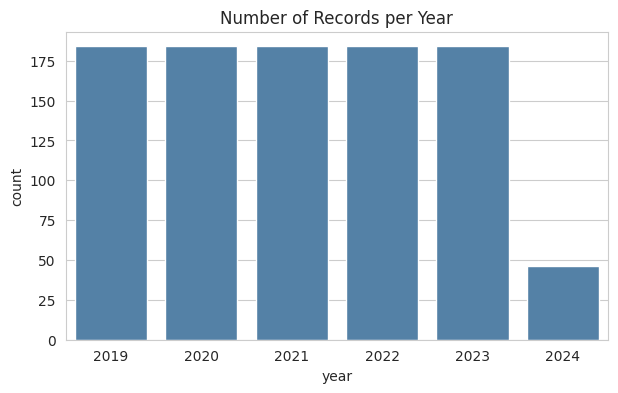

In [ ]:
plt.figure(figsize=(7, 4))
sns.countplot(data=df_all, x='year', color='steelblue')
plt.title('Number of Records per Year')
plt.show()

**Insights**

- Bars show how many records exist for each year (2019 to 2024).

- Bars are about equal, every year is covered evenly and comparisons across years are fair.
-  Shorter bar means fewer quarters or states were reported that year

Features used

- year

It shows

 - The data is balanced across time, so the 2019 to 2022 comparison is not biased by uneven coverage.




**Analysis about Records per gender**

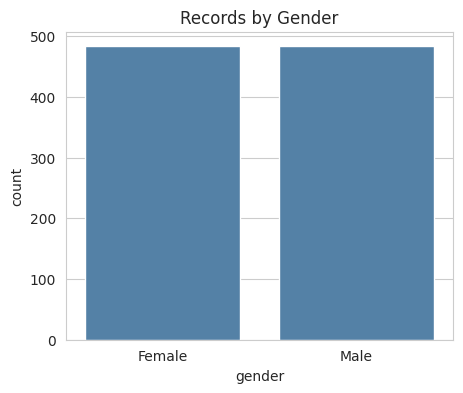

In [ ]:
plt.figure(figsize=(5, 4))
sns.countplot(data=df_all, x='gender', color='steelblue')
plt.title('Records by Gender')
plt.show()

**Insights**


- Bars show the number of records for each gender category (Male and Female)
- Equal bars mean each group is equally represented

Features used

- gender

It shows

- Neither gender is under-represented, so gender comparisons are reliable




**Analysis about LFPR Distribution**

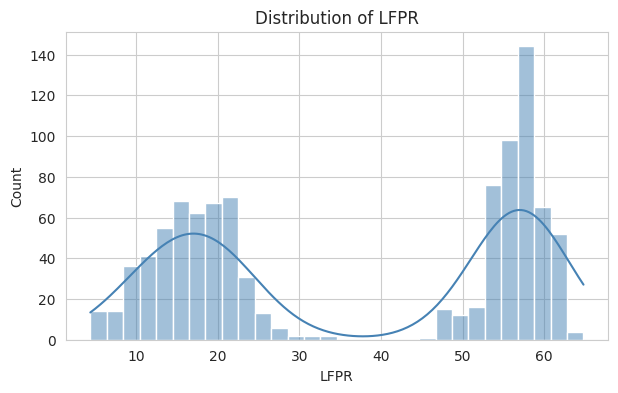

In [ ]:
plt.figure(figsize=(7, 4))
sns.histplot(df_all['LFPR'], bins=30, kde=True, color='steelblue')
plt.title('Distribution of LFPR')
plt.show()

**Insights**


- It has two separate peaks: one at about 15 to 20% and one at about 55 to 58%, with almost no records between 30 and 47%.
- The lower peak is the female group and the higher, taller peak is the male group, which matches  pairplot.
- overall skewness of 0.10 looks symmetric

Features used

- lfpr

It shows

LFPR is not one population. Gender splits it into two groups, so an overall mean (about 37) describes neither group.




**Analysis about Distribution of Unemployment Rate**

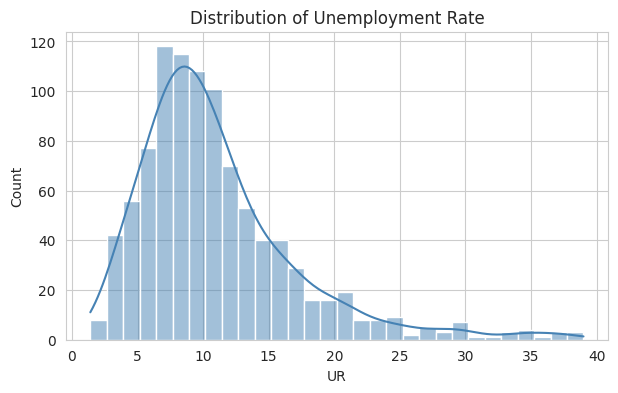

In [ ]:
plt.figure(figsize=(7, 4))
sns.histplot(df_all['UR'], bins=30, kde=True, color='steelblue')
plt.title('Distribution of Unemployment Rate')
plt.show()

**Insights**


*  The distribution is right-skewed (skewness 1.42). It peaks at about 7 to 9%, with roughly 115 to 120 records per bar.
* Most records fall between 5 and 15%.
- A long thin tail runs from 20% up to about 39%, with small bumps at 30 to 39%.

Features used

- UR (all genders, age_group = All)

It shows

- Typical unemployment is moderate, but a small number of extreme cases (high-unemployment states and the pandemic quarters) pull the mean above the median. Use the median to describe a "typical" value.




**Analysis about Distribution of Agriculture Employment Share**

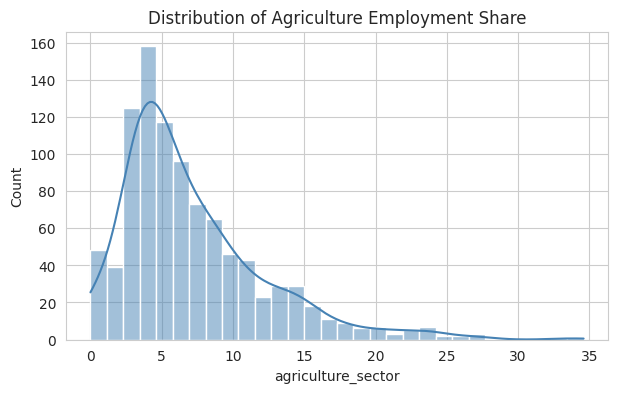

In [ ]:
plt.figure(figsize=(7, 4))
sns.histplot(df_all['agriculture_sector'], bins=30, kde=True, color='steelblue')
plt.title('Distribution of Agriculture Employment Share')
plt.show()

**Insights**


- It is strongly right-skewed (skewness 1.67). The peak is at about 4 to 5% (the tallest bar, about 158 records), and most values lie below 10%.
- A long tail reaches about 35%.
- About 45 to 50 records sit at 0%. Those may be real zeros or filled-in values, so check them.

Features used

- agriculture_sector

It shows

- Agriculture is a small employer in most of these records, and only a few states or quarters have a high share.




**Analysis about LFPR, UR and WPR**

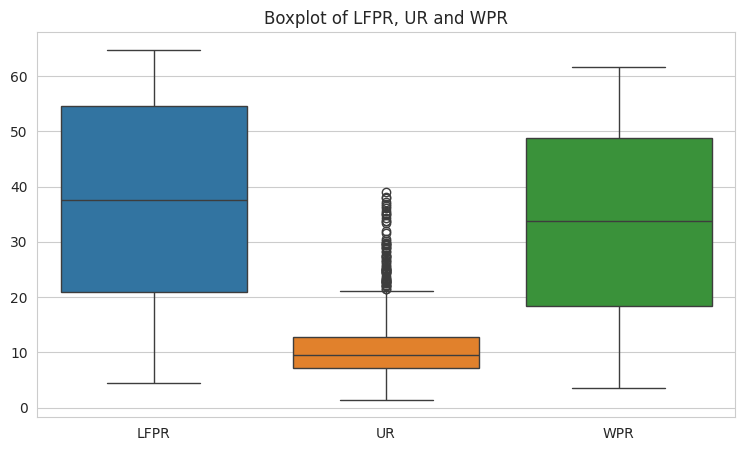

In [ ]:
sns.boxplot(data=base[['LFPR', 'UR', 'WPR']])
plt.title('Boxplot of LFPR, UR and WPR')
plt.show()

**Insights**


- LFPR: median about 37, box about 21 to 54, wide spread, no outliers.
- WPR: median about 34, box about 18 to 48, similar wide spread, no outliers.
- UR: median about 9 to 10, a compact box of about 7 to 13, and many outliers from 21 up to 39.
- The wide LFPR and WPR boxes come from combining male and female values in one chart.

Features used

- LFPR, UR, WPR

It shows

- Unemployment is the only indicator with true extreme values, and it is concentrated near the low end.
- The huge LFPR and WPR spread is a gender effect, not noise.
- The UR outliers are genuine high-unemployment cases, which supports your decision to retain them.
- UR is on a different scale from LFPR and WPR, so compare spreads within each indicator, not across them.




**Analysis about Sector Employment share comparison**

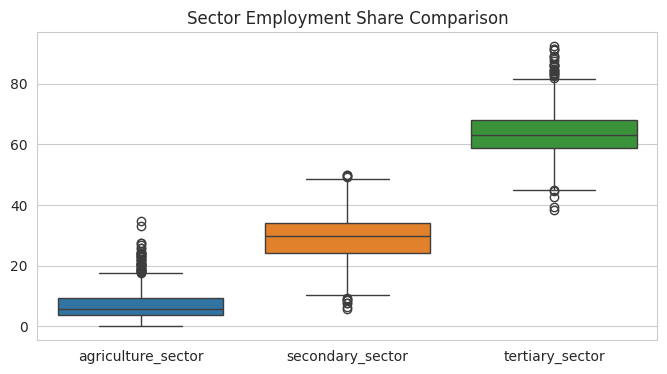

In [ ]:
#Sector shares

plt.figure(figsize=(8, 4))
sns.boxplot(data=df_all[['agriculture_sector', 'secondary_sector', 'tertiary_sector']])
plt.title('Sector Employment Share Comparison')
plt.show()

**Insights**


-Tertiary is the largest: median about 63%, box about 59 to 68%, with outliers up to about 92% and some low ones around 38 to 45%.
- Secondary is in the middle: median about 30%, box about 24 to 34%, with a few outliers near 6 to 9% and 50%.
- Agriculture is the smallest: median about 6%, box about 4 to 9%, with many high outliers up to about 35%.

Features used

- agriculture_sector, secondary_sector, tertiary_sector.

It shows

- The workforce in this data is dominated by services, followed by industry, with agriculture a distant third.
- Only agriculture shows many high-side outliers, so a few states depart a lot from the national pattern.




# Bivariate Analysis

In [ ]:
# 'Person' = combined male + female, so each state appears once per quarter
person = base[base['gender'] == 'Person'].copy()

**Analysis about Average  Unemployment Rate by state**

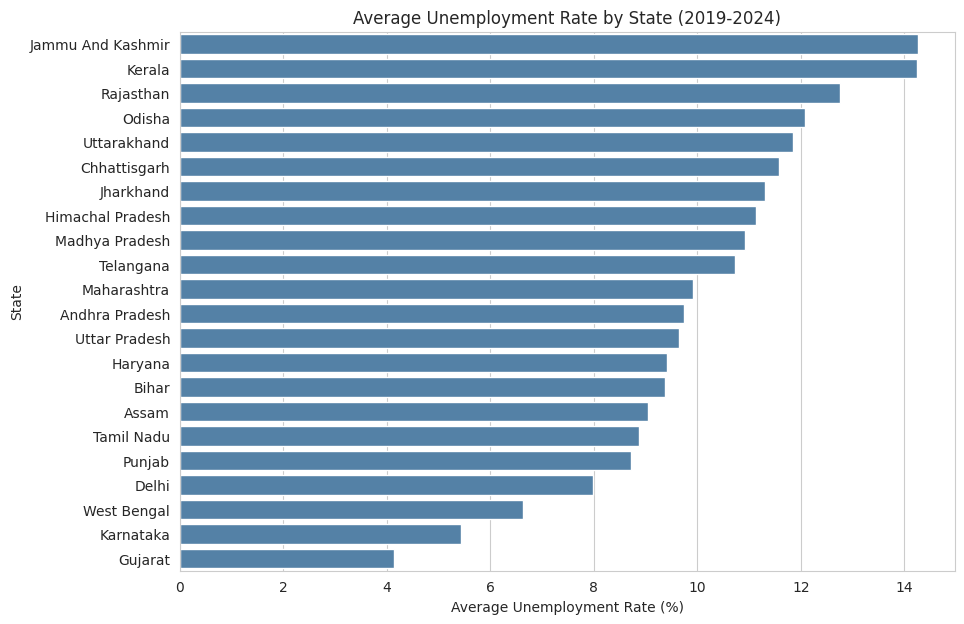

In [ ]:
state_ur = person.groupby('state_name')['UR'].mean().sort_values(ascending=False)

plt.figure(figsize=(10, 7))
sns.barplot(x=state_ur.values, y=state_ur.index, color='steelblue')
plt.xlabel('Average Unemployment Rate (%)')
plt.ylabel('State')
plt.title('Average Unemployment Rate by State (2019-2024)')
plt.show()

**Insights**
- Each bar is a state's average unemployment rate over all years, sorted from highest to lowest
- Jammu and Kashmir and Kerala are at the top and almost equal, clearly above everyone else.
- Rajasthan, Odisha, Uttarakhand, Chhattisgarh and Jharkhand follow as a high group.
- West Bengal, Delhi, Punjab and Tamil Nadu have the lowest averages among the visible states.

Features used:
- state_name and UR (mean).

It shows:
- Unemployment is persistently higher in some states, not only during the pandemic. This matches the heatmap, where Jammu and Kashmir and Kerala were dark in almost every year.

**Analysis about Average LFPR by Gender**

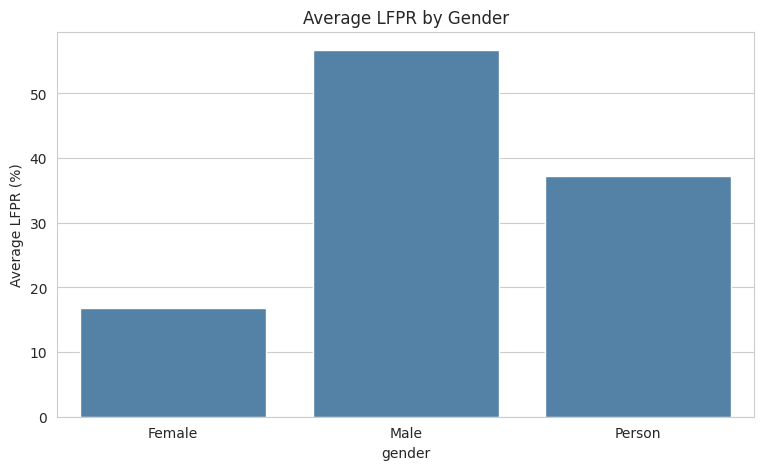

In [ ]:
#Average LFPR by gender

sns.barplot(data=base, x='gender', y='LFPR', errorbar=None, color='steelblue')
plt.title('Average LFPR by Gender')
plt.ylabel('Average LFPR (%)')
plt.show()

**Insights**
- Bars compare the average participation rate for Female, Male and Person
- Male is about 57%, Female is about 17%, and Person sits in between at about 37%.
- Male participation is more than three times female participation.

Features used:
- gender and LFPR (mean)

It shows:
- There is a very large gender gap in labour force participation, so most women are outside the labour force.

### Analysis about Average Unemployment Rate by Phase

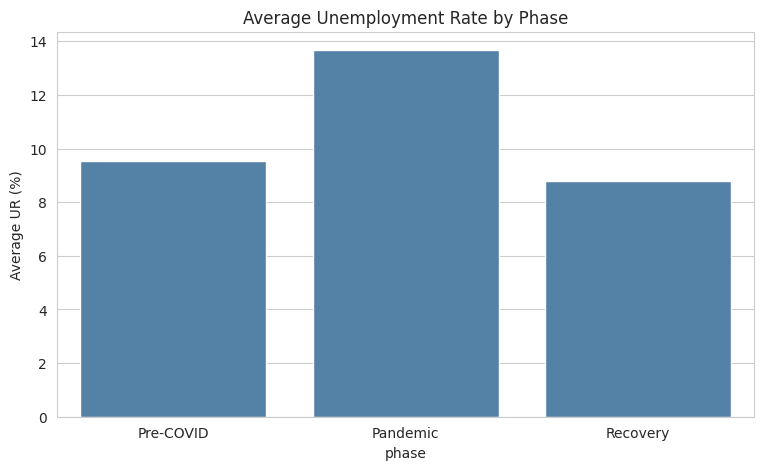

In [ ]:
#Average UR by phase

phase_data = person.dropna(subset=['phase'])

sns.barplot(data=phase_data, x='phase', y='UR', order=['Pre-COVID', 'Pandemic', 'Recovery'],
            errorbar=None, color='steelblue')
plt.title('Average Unemployment Rate by Phase')
plt.ylabel('Average UR (%)')
plt.show()

**Insights**
- Bars compare average unemployment across the three phases
- Pre-COVID is about 9.5%, the pandemic is about 13.7% and recovery is about 8.8%.
- The pandemic raised UR by roughly 4 points, which is about a 43% increase.
- Recovery ended slightly below the pre-COVID level

Features used:
- phase and UR (mean)

It shows:
- A sharp shock followed by a full recovery
- The recovery went beyond the pre-pandemic level, so the labour market improved on its starting point.

### Analysis about LFPR vs WPR

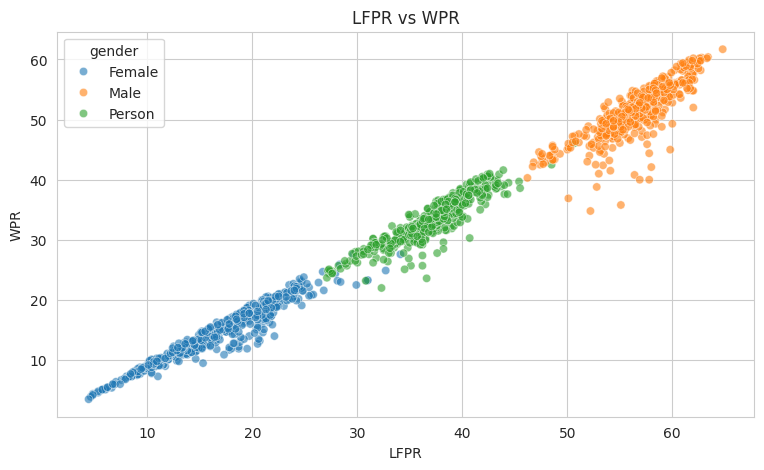

In [ ]:
#LFPR vs WPR

sns.scatterplot(data=base, x='LFPR', y='WPR', hue='gender', alpha=0.6)
plt.title('LFPR vs WPR')
plt.show()

**Insights**
- A very tight upward straight line, with a correlation of about 0.99.
- Female points sit at the lower left, Person in the middle, and Male at the upper right.
- Male points spread out below the line at LFPR 50 to 55, where WPR drops to 35 to 45. These are records with high unemployment.

Features used:
- LFPR, WPR and gender

It shows:
- WPR is almost fully determined by LFPR, because WPR is LFPR adjusted for unemployment. The distance below the line reflects UR.

### Analysis about Unemployment Rate vs Tertiary Sector Share

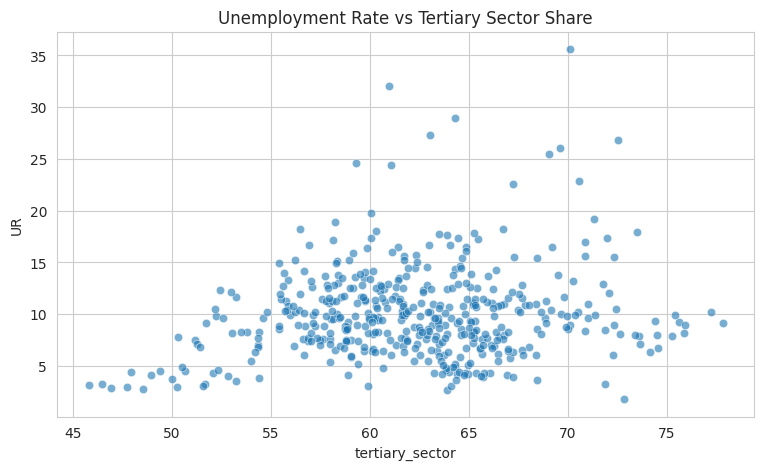

In [ ]:
#UR vs tertiary sector share

sns.scatterplot(data=person, x='tertiary_sector', y='UR', alpha=0.6)
plt.title('Unemployment Rate vs Tertiary Sector Share')
plt.show()

**Insights**
- There is no clear relationship. The cloud is wide, with most points at tertiary 55 to 70 and UR 5 to 15.
- A slight upward drift appears at the low end: points below about 52% tertiary have low UR (about 3 to 5).
- Beyond 55%, a higher services share does not lower or raise unemployment in a consistent way.
- The extreme UR values (25 to 35) occur at mid-to-high tertiary shares, so they are not explained by sector structure.

Features used:
- tertiary_sector and UR

It shows:
- A bigger services sector does not guarantee lower unemployment. Other factors matter, which supports the state-by-state approach.

### Analysing correlation heatmap for Labour Indicators

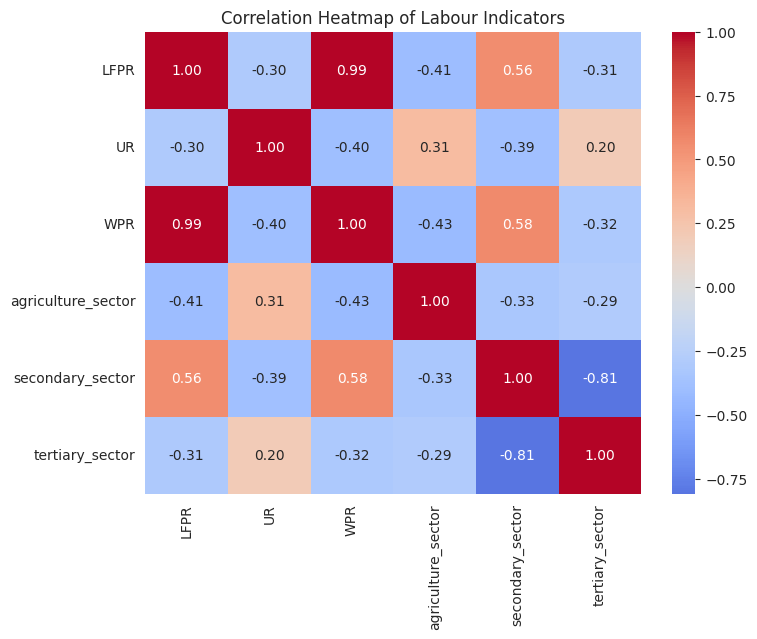

In [ ]:
cols = ['LFPR', 'UR', 'WPR', 'agriculture_sector', 'secondary_sector', 'tertiary_sector']

plt.figure(figsize=(8, 6))
sns.heatmap(base[cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation Heatmap of Labour Indicators')
plt.show()

**Insights**
- Each cell gives the correlation (-1 to +1) between two variables. Dark red is strongly positive and dark blue is strongly negative.
- LFPR and WPR: 0.99. They are almost identical.
- UR is moderately negative with LFPR and WPR (-0.30, -0.40). -Higher unemployment goes with lower participation and a lower worker ratio.
- Agriculture-heavy states do worse (-0.41 with LFPR, -0.43 with WPR). The more a state depends on farming, the lower its participation and employment.
- Secondary-sector states do better (0.56 with LFPR, 0.58 with WPR). States with more industry and manufacturing have higher participation and employment.
-Secondary and tertiary shares trade off (-0.81). When one grows, the other shrinks, partly because the shares add up to 100%.

Features used:
- LFPR, UR, WPR, agriculture_sector, secondary_sector, tertiary_sector

It shows:
- None of these relationships is above about 0.6 apart from LFPR/WPR, so they are moderate at best.

## Multivariate Analysis

### Analysis about (LFPR, UR, WPR by gender)

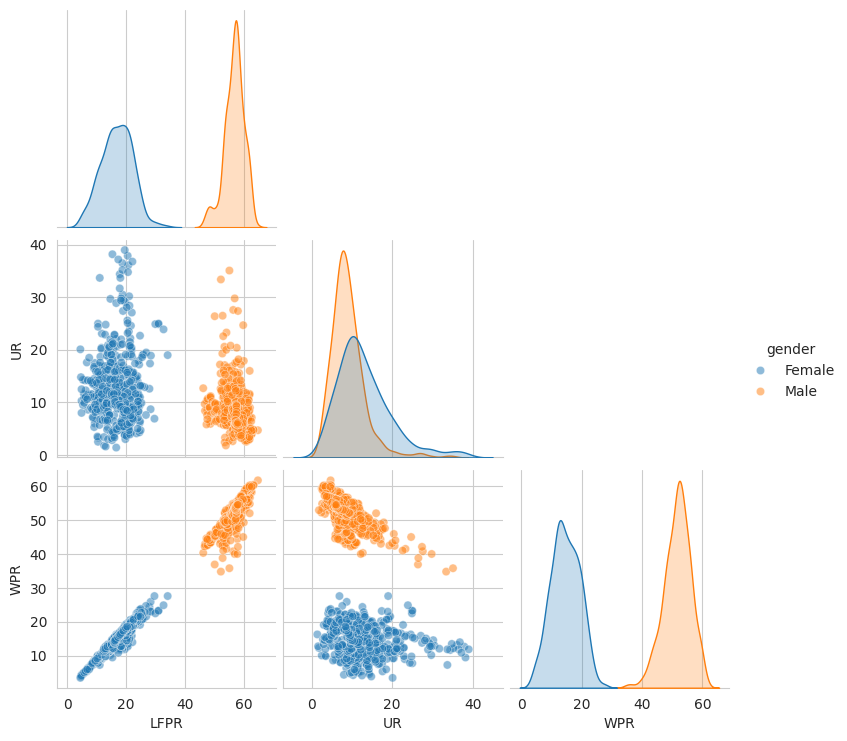

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
df_all = df[(df['age_group'] == 'All') & (df['gender'].isin(['Male', 'Female']))].copy()
sns.pairplot(df_all, vars=['LFPR', 'UR', 'WPR'], hue='gender',
             diag_kind='kde', corner=True, plot_kws={'alpha': 0.5})
plt.show()

**Insights**

* A grid of scatterplots (pairs) and KDE curves (diagonal) for LFPR, UR and WPR.

* Blue is female and orange is male.

* Gender separation: the two colours form separate clusters on every LFPR and WPR panel. Male LFPR and WPR sit around 50–60, while female sits around 15–25.

* LFPR vs WPR: a strong positive straight line for both genders. Where participation is higher, more people are actually working.
UR distribution: female UR is right-skewed with a long tail up to about 40, and it is more spread out. Male UR is tighter, mostly 5–15.

* UR vs WPR: for males there is a clear negative slope, so higher unemployment goes with lower worker ratios. For females it is flat and scattered.

* UR vs LFPR: no clear pattern, since the points separate only by gender.

Features used:
- LFPR, UR, WPR, with gender as the colour. Filtered to age_group = All.

 It shows:
 - Female unemployment is more volatile across states and quarters, while the male labour market is more stable.

### Grouped analysis (phase × gender)

In [ ]:
grp = (df_all.dropna(subset=['phase'])
             .groupby(['phase', 'gender'])[['LFPR', 'UR', 'WPR']].mean().round(2))
print(grp)

                     LFPR     UR    WPR
phase       gender                     
Other Years Female  17.74  12.20  15.53
            Male    57.08   8.04  52.53
Pandemic    Female  16.14  15.77  13.61
            Male    56.43  13.00  48.93
Pre-COVID   Female  15.27  12.83  13.29
            Male    56.15   8.53  51.40
Recovery    Female  16.67  12.39  14.60
            Male    56.80   7.73  52.44


**Insights**

*   Shock: male UR rose by about 4.5 points, while female UR rose by about 3 points.

* Male WPR: it fell by about 2.5 points in the pandemic, so men lost jobs.
* Female WPR: it did not fall. It rose slightly.
* Recovery: UR fell below pre-COVID levels for both genders, and   WPR is above pre-COVID levels for both.
* LFPR: it barely changed (male about 56, female 15 to 17), so the shock hit employment, not participation.
* Gap: female UR stayed higher than male UR in every phase

 Features used:
 - phase and gender (grouping), LFPR, UR and WPR (means)

It shows:
- The pandemic hit men's employment hardest, and the recovery fully reversed it.
Women's participation and employment kept rising, but their unemployment stayed structurally higher.


### Analysis about Unemployment Rate by State and Year

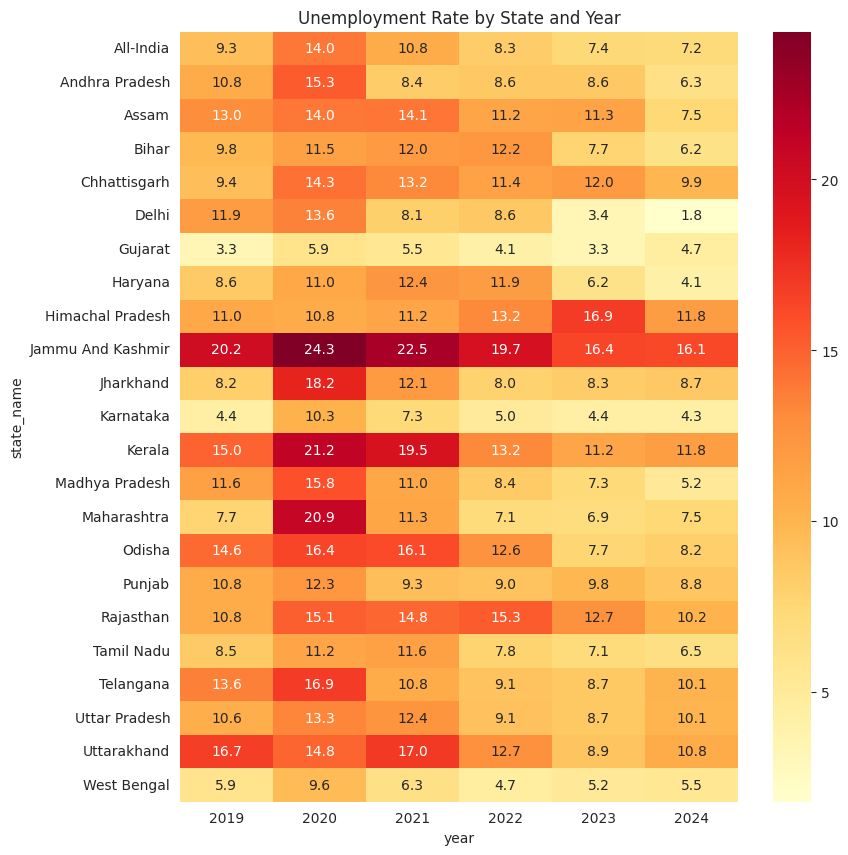

In [ ]:
#Pivot table and heatmap (state × year, UR)

pv_ur = df_all.pivot_table(values='UR', index='state_name', columns='year', aggfunc='mean').round(2)

plt.figure(figsize=(9, 10))
sns.heatmap(pv_ur, annot=True, fmt='.1f', cmap='YlOrRd')
plt.title('Unemployment Rate by State and Year')
plt.show()

**Insights**

*  Rows are states and columns are years and the colour is the average UR. Darker red means higher unemployment.

- Sharpest shocks:
Maharashtra: 7.7 to 20.9 (+13.2 points).
Jharkhand: 8.2 to 18.2 (+10.0).
Kerala: 15.0 to 21.2.
Karnataka: 4.4 to 10.3.
- Fastest recoveries: Maharashtra (7.5 in 2024), Jharkhand (8.7), Karnataka (4.3), Madhya Pradesh (5.2) and Andhra Pradesh (6.3) all returned to or below their 2019 level.
- Slow recovery:
Kerala stayed at 19.5 in 2021, and was still 11.8 in 2024.
Rajasthan peaked later, at 15.3 in 2022.
Chhattisgarh stayed at 11 to 14 for four years.
Bihar peaked in 2022 (12.2) rather than 2020.
- Persistently high: Jammu and Kashmir is the darkest row throughout (20.2, 24.3, 22.5, 19.7, 16.4, 16.1). It is always the highest, even though it improved.
- Stable and low: Gujarat (3.3 to 5.9, ending at 4.7), West Bengal (4.7 to 9.6) and Delhi, which ends at 1.8, the lowest value on the chart.
- Different pattern: Himachal Pradesh has no 2020 spike. Its UR rises to 16.9 in a later year, so it is a delayed shock.
- Structural improvement: Odisha (14.6 to 8.2) and Uttarakhand (16.7 to 10.8) ended well below where they started.

Features used:
- state_name, year, UR (averaged).

 It shows:
 - 2020 was the common shock year, and most states recovered by 2022 to 2024.
- Sharp shock, fast recovery: Maharashtra, Jharkhand, Karnataka.
- Persistently high: Jammu and Kashmir, Kerala, Himachal Pradesh.
- Stable and low: Gujarat, West Bengal, Delhi.


### Analysis about LFPR vs UR by sector shares

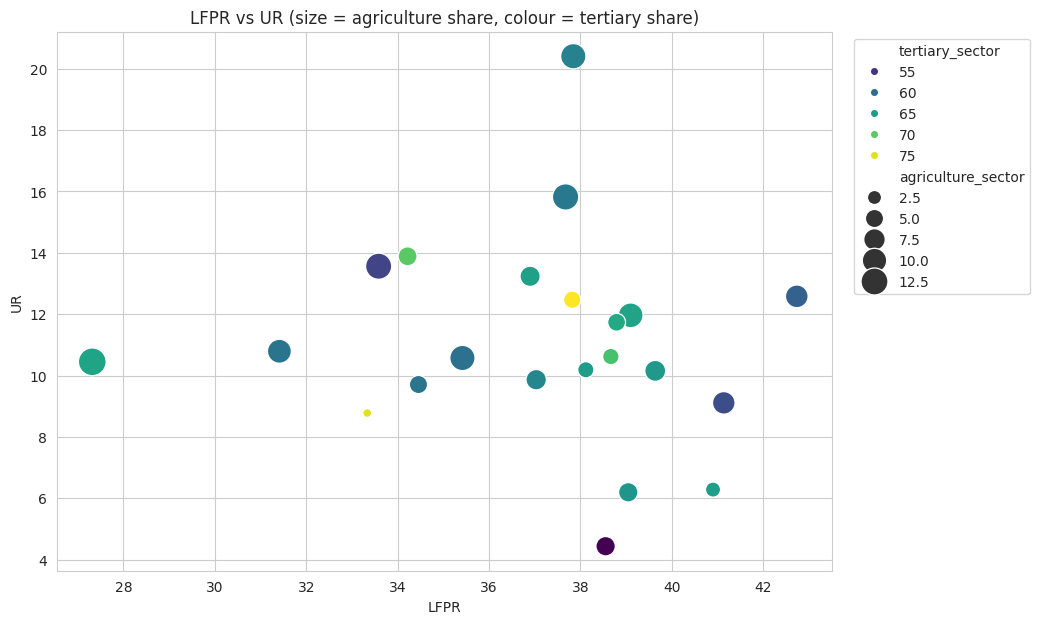

In [ ]:
#Advanced plot

state_avg = df_all.groupby('state_name')[['LFPR', 'UR', 'agriculture_sector', 'tertiary_sector']].mean().reset_index()

plt.figure(figsize=(10, 7))
sns.scatterplot(data=state_avg, x='LFPR', y='UR', size='agriculture_sector',
                hue='tertiary_sector', palette='viridis', sizes=(40, 400))
plt.title('LFPR vs UR (size = agriculture share, colour = tertiary share)')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.show()

**Insights**

*   Each dot is a state. The position shows LFPR and UR, the size shows agriculture share, and the colour shows tertiary share (yellow is high, dark blue is low).

*  The dots are spread out with no clear line, so LFPR and UR are not strongly related at state level.
* The small yellow dots are states with high tertiary and low agriculture share. They sit mid-to-low on UR.
* The larger teal and blue dots (agriculture-heavy) are spread across all positions, so agriculture share alone does not decide unemployment.

Features used:
- State averages of LFPR, UR, agriculture_sector and tertiary_sector

 It shows:
 - Economic structure alone does not explain unemployment. Participation and unemployment depend on other state-specific factors.

**1. Descriptive Analysis**

•	Analysed average LFPR, UR and WPR and their distributions.

•	Compared labour market indicators across states, genders, age groups and the three phases.

•	Examined the trend in unemployment and participation from 2019 to 2024.

•	Described sector-wise employment shares across states.



**2. Diagnostic Analysis**

•	Investigated how sector structure relates to participation and unemployment: agriculture-heavy states show weaker outcomes and secondary-sector states stronger ones.

•	Found that LFPR and WPR move almost together (0.99), while unemployment shows only moderate negative relationships.

•	Showed that sector structure alone does not explain unemployment; no clear relationship appears between tertiary share and UR.

•	Identified states with a sharp shock and fast recovery (Maharashtra, Jharkhand, Karnataka) versus persistently high unemployment (Jammu and Kashmir, Kerala).


**3. Predictive Analysis**

Historical phase-wise patterns can help monitor how states may respond to future shocks. However, this project focuses on descriptive and diagnostic analysis using basic statistics, not predictive modelling.

**4. Prescriptive Analysis**

•	Prioritize the states still above their pre-COVID unemployment level.

•	Support women's participation and reduce the gap in unemployment between women and men.

•	Promote non-farm employment, since agriculture-heavy states show weaker outcomes.

•	Learn from states that recovered best and monitor unemployment together with participation.


# Stage 4: Dashboard

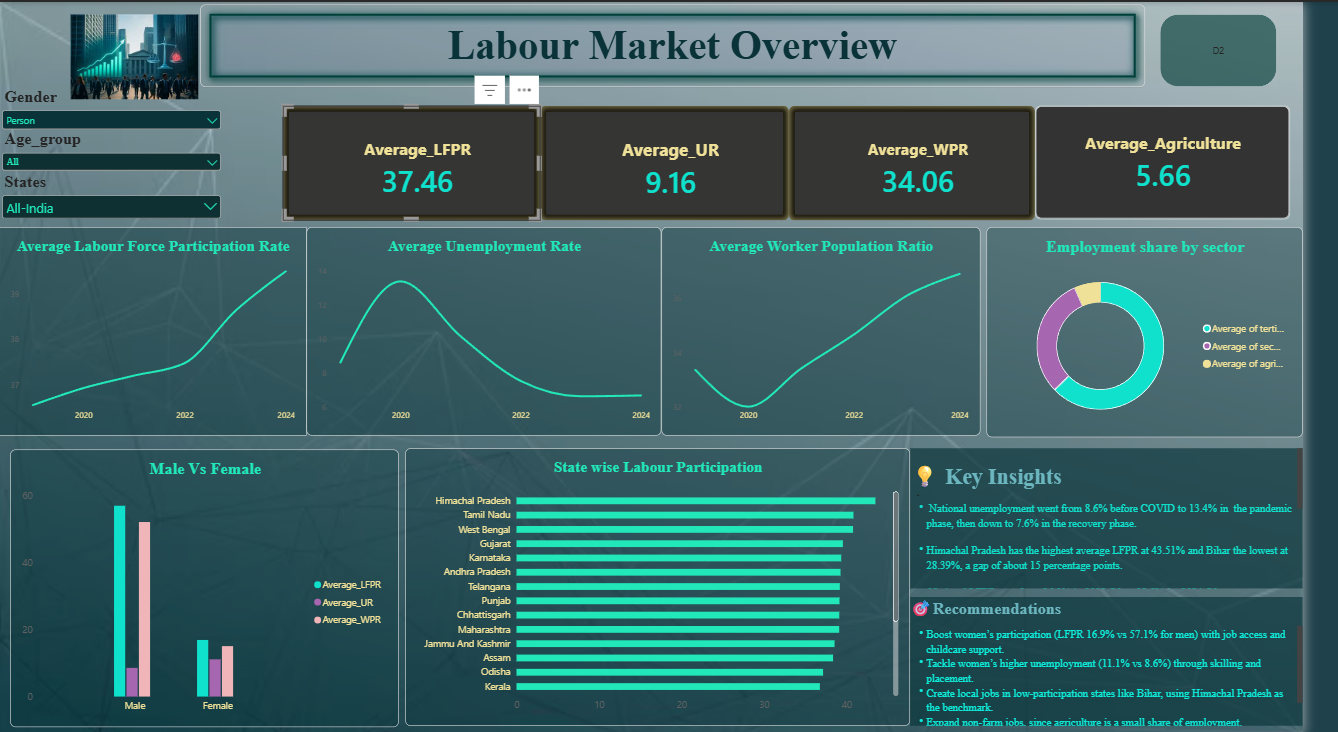

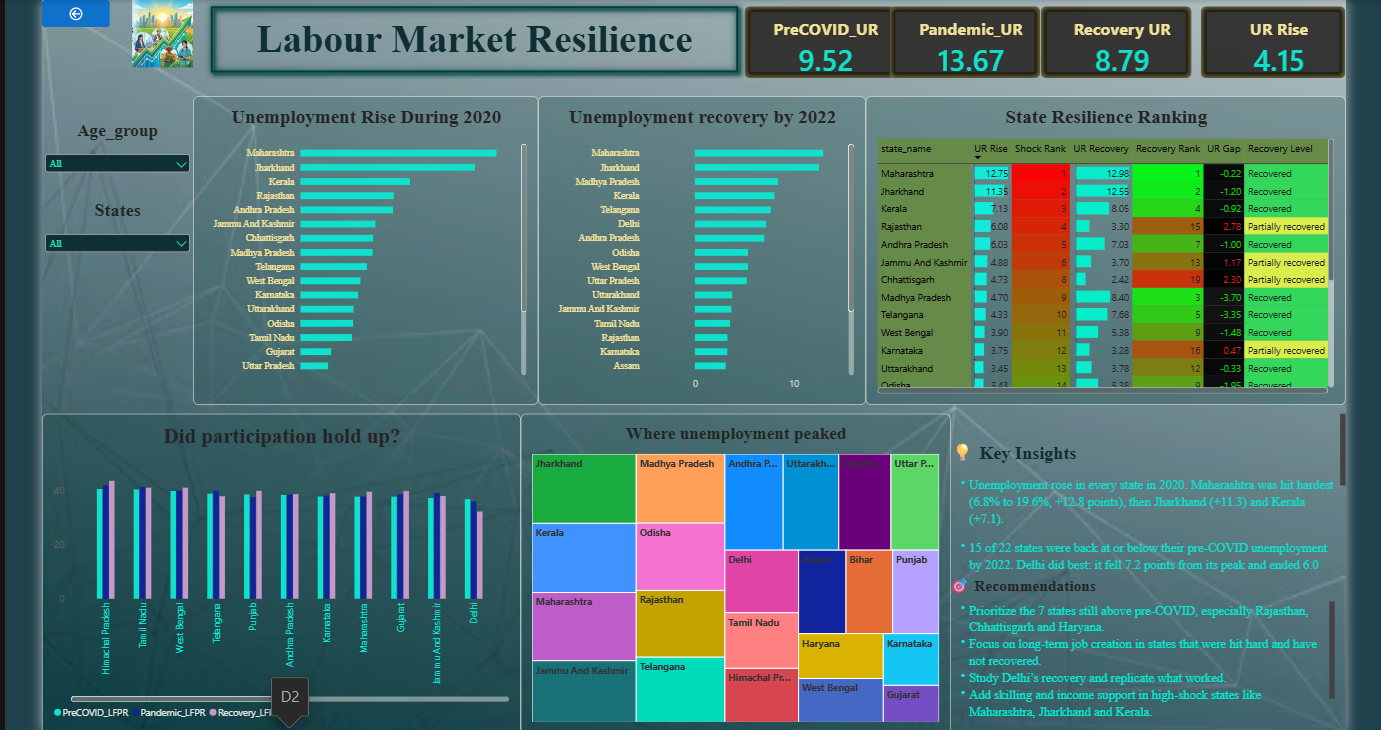

# Final Insights

- Unemployment rose from ~9.5% (pre-COVID) to ~13.7% (pandemic), then fell to ~8.8% (recovery).
- Male LFPR is ~57% vs ~17% for females, and the gap barely changed.
- Men lost more jobs in the pandemic; female unemployment stayed higher overall.
- J&K, Kerala, Rajasthan and Odisha have the highest unemployment; West Bengal, Delhi and Karnataka the lowest.
- Most states peaked in 2020, then eased.
- Secondary-sector states do better; agriculture-heavy states do worse.
- LFPR and WPR move almost together (0.99).

# Conclusion
- COVID caused a sharp but temporary rise in unemployment, and the market recovered fully.
- The gender gap and state differences remain.
- Policy should focus on women's participation, non-farm jobs and high-unemployment states.